# 01 — Exploratory Data Analysis

Dataset: **LexGLUE `unfair_tos`** — sentences from 50 real Terms of Service, labeled with 8 categories of potentially unfair clauses.

Goal: understand the data before modeling — class balance, label distribution, sentence length and vocabulary — and decide **which metric** to optimize.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from clausula.data import load_splits
from clausula.labels import LABELS

splits = load_splits()
train, val, test = splits["train"], splits["validation"], splits["test"]
train.head()

/home/davig/clausula/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,text,labels,Limitation of liability,Unilateral termination,Unilateral change,Content removal,Contract by using,Choice of law,Jurisdiction,Arbitration,is_unfair
0,notice to california subscribers : you may can...,[],0,0,0,0,0,0,0,0,0
1,"if you subscribed using your apple id , refund...",[],0,0,0,0,0,0,0,0,0
2,"if you wish to request a refund , please visit...",[],0,0,0,0,0,0,0,0,0
3,if you subscribed using your google play store...,[],0,0,0,0,0,0,0,0,0
4,key changes in this version : we 've included ...,[],0,0,0,0,0,0,0,0,0


## 1. How many sentences are unfair? Is it similar across splits?

In [2]:
summary = pd.DataFrame({
    name: {"sentences": len(df), "unfair": df["is_unfair"].sum(), "unfair %": round(df["is_unfair"].mean() * 100, 1)}
    for name, df in splits.items()
}).T
summary

,sentences,unfair,unfair %
train,5532.0,630.0,11.4
validation,2275.0,230.0,10.1
test,1607.0,172.0,10.7


## 2. Sentences per category

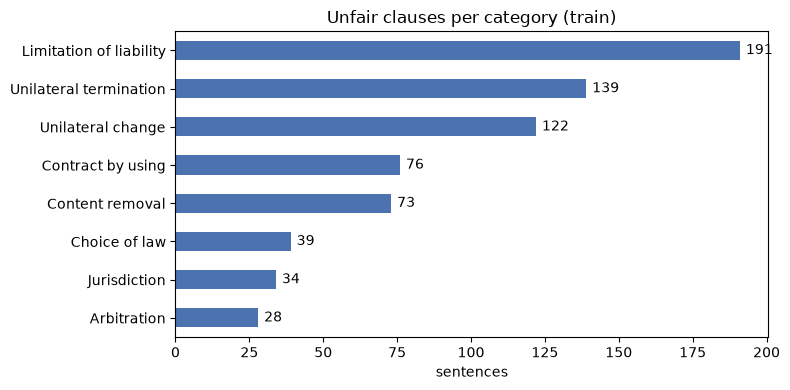

,train,validation,test
Limitation of liability,191,67,38
Unilateral termination,139,59,38
Unilateral change,122,28,38
Contract by using,76,18,23
Content removal,73,32,13
Choice of law,39,18,13
Jurisdiction,34,18,16
Arbitration,28,9,7


In [3]:
counts = pd.DataFrame({name: df[LABELS].sum() for name, df in splits.items()})
counts = counts.sort_values("train")

ax = counts["train"].plot.barh(figsize=(8, 4), color="#4C72B0")
ax.set_title("Unfair clauses per category (train)")
ax.set_xlabel("sentences")
for i, v in enumerate(counts["train"]):
    ax.text(v + 2, i, str(v), va="center")
plt.tight_layout()
plt.show()

counts.sort_values("train", ascending=False)

In [4]:
n_labels = train[LABELS].sum(axis=1)
print("Sentences with more than one category:", (n_labels > 1).sum())
n_labels[n_labels > 0].value_counts().sort_index()

Sentences with more than one category: 63


1    567
2     54
3      9
Name: count, dtype: int64

## 3. Sentence length — are unfair sentences longer?

            count  mean   std  min   25%   50%   75%    max
is_unfair                                                  
0          4902.0  31.1  23.2  6.0  17.0  26.0  38.0  441.0
1           630.0  41.8  32.7  6.0  23.0  32.0  50.0  353.0


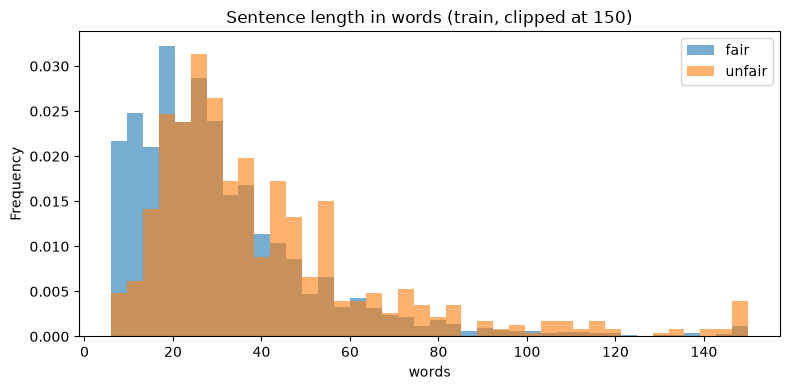

In [5]:
for df in splits.values():
    df["n_words"] = df["text"].str.split().str.len()

print(train.groupby("is_unfair")["n_words"].describe().round(1))

fig, ax = plt.subplots(figsize=(8, 4))
for flag, name in [(0, "fair"), (1, "unfair")]:
    train.loc[train["is_unfair"] == flag, "n_words"].clip(upper=150).plot.hist(
        bins=40, alpha=0.6, density=True, ax=ax, label=name)
ax.set_title("Sentence length in words (train, clipped at 150)")
ax.set_xlabel("words")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Examples and the words that give each category away

In [6]:
pd.set_option("display.max_colwidth", 250)
for label in LABELS:
    print(f"\n=== {label} ===")
    for text in train.loc[train[label] == 1, "text"].sample(3, random_state=42):
        print("-", text[:250])


=== Limitation of liability ===
- to the extent permissible under applicable law , spotify reserves the right , periodically and at any time , to modify or discontinue , temporarily or permanently , functions and features of the spotify service , with or without notice , all without 
- note that it is your responsibility to be aware of such notices , and you hereby acknowledge and agree that blizzard entertainment shall not be responsible for any damages which may arise from your failure to read and/or be aware of these publicly po
- as such , we are not liable for any damage or loss caused or alleged to be caused by or in connection with the use of or reliance on any such social networking services .

=== Unilateral termination ===
- we may suspend , or terminate your access to or use of our services anytime for any reason , such as if you violate the letter or spirit of our terms and polices , or create harm , risk , or possible legal exposure for us , our users , or others .
- viol

To find the giveaway words, we compare how often each word appears **inside** a category vs. in the rest of the data (a simple log-odds ratio). High score = word strongly associated with that category.

In [7]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

vec = CountVectorizer(stop_words="english", min_df=3, binary=True)
X = vec.fit_transform(train["text"])
vocab = np.array(vec.get_feature_names_out())

def top_words(label, n=8):
    mask = train[label].values == 1
    in_cat = np.asarray(X[mask].sum(axis=0)).ravel() + 1
    out_cat = np.asarray(X[~mask].sum(axis=0)).ravel() + 1
    score = np.log(in_cat / mask.sum()) - np.log(out_cat / (~mask).sum())
    return ", ".join(vocab[np.argsort(score)[::-1][:n]])

pd.DataFrame({"top words": {label: top_words(label) for label in LABELS}})

,top words
Limitation of liability,"punitive, exemplary, inability, 100, possibility, advised, profits, indirect"
Unilateral termination,"suspend, breached, spirit, violated, exposure, terminating, repeatedly, letter"
Unilateral change,"revise, amend, eliminate, regulate, impose, anytime, adding, enhancements"
Content removal,"disallow, regulate, breached, allegations, usernames, reclaim, eliminate, block"
Contract by using,"continued, bound, acceptance, acknowledgment, understood, browsing, installing, continuing"
Choice of law,"principles, conflicts, governed, regard, construed, nations, conflict, england"
Jurisdiction,"northern, litigating, mateo, district, clara, santa, courts, exclusively"
Arbitration,"settled, decided, jams, resolving, chamber, finally, negotiation, involves"


## 5. The metric question: what does a model that always says "fair" score?

In [8]:
from sklearn.metrics import accuracy_score, f1_score

y_true = test[LABELS].values
y_dummy = np.zeros_like(y_true)  # predicts "fair" for every sentence

print("Accuracy (sentence is fair/unfair):", round(accuracy_score(test["is_unfair"], np.zeros(len(test))), 3))
print("Macro F1 over the 8 categories:   ", round(f1_score(y_true, y_dummy, average="macro", zero_division=0), 3))

Accuracy (sentence is fair/unfair): 0.893
Macro F1 over the 8 categories:    0.0


## Conclusions

1. **Heavy imbalance:** only ~11% of sentences are unfair (11.4% train, 10.1% val, 10.7% test). The proportion is stable across splits, so the splits are comparable.
2. **Long tail of categories:** *Limitation of liability* has 191 training examples, *Arbitration* only 28. Rare categories will be the hardest; we must report metrics **per category**, not just an average. 63 sentences have 2–3 categories → this is a **multi-label** problem.
3. **Unfair sentences are longer** (median 32 vs. 26 words). Length alone is a weak signal, but it suggests legal boilerplate. Some sentences reach 350–440 words, which matters for transformer max length (≈512 tokens).
4. **Strong lexical cues:** *governed / construed / conflicts* → Choice of law; *suspend / terminating* → Unilateral termination; *continued / bound / acceptance* → Contract by using. A TF-IDF baseline should do reasonably well.
   ⚠️ But *Jurisdiction* is associated with *santa, clara, mateo* — company-specific place names (Silicon Valley courts). A model can memorize these and fail on ToS from other companies → we need to watch generalization.
   ⚠️ Labels overlap: some *Limitation of liability* examples read like *Unilateral change* — expect some label noise.
5. **Accuracy is misleading:** a model that always predicts "fair" gets **89.3% accuracy** but **0.0 macro-F1** — it never finds a single unfair clause. We will optimize **macro-F1** (each category weighs the same) and also track micro-F1 and per-category precision/recall.

**Note:** the text is already lowercased and tokenized (`we 've`, spaces before punctuation). Real ToS pasted by users won't be — we must apply the same normalization at inference time.
